*Part 1.*

Implement Selection-, Insertion- and Merge sort in Python.

All three algorithms must be tested with comprehensive tests.

In [16]:
arrayX = [29,72,98,13,87]

def selection_sort(array: list) -> list:
    length = len(array)
    for i in range(length-1):
        min_val = i
        for j in range(i+1,length):
            if array[j] < array[min_val]:
                min_val = j
        if min_val != i:
            array[i], array[min_val] = array[min_val], array[i]

    return array

print("Selection sort:", selection_sort(arrayX))

def insertion_sort(array:list) -> list:
    for i in range(1, len(array)):
        key = array[i]
        j = i-1
        while j >= 0 and key < array[j]:
            array[j+1] = array[j]
            j -= 1
        array[j+1] = key

    return array

print("Insertion sort:", insertion_sort(arrayX))

def merge_sort(array:list) -> list:
    if len(array) <=1:
        return array

    mid = len(array) // 2
    left = merge_sort(array[:mid])
    right = merge_sort(array[mid:])

    return merge(left, right)

def merge(left: list, right: list) -> list:
    sorted = []
    i = j = 0

    while i < len(left) and j < len(right):
        if left[i] <= right[j]:
            sorted.append(left[i])
            i += 1
        else:
            sorted.append(right[j])
            j += 1

    sorted.extend(left[i:])
    sorted.extend(right[j:])

    return sorted

print("Merge sort:", merge_sort(arrayX))

Selection sort: [13, 29, 72, 87, 98]
Insertion sort: [13, 29, 72, 87, 98]
Merge sort: [13, 29, 72, 87, 98]


In [17]:
import random
import unittest
from collections import namedtuple


class SortTests:
    """Shared tests run against every sorting algorithm. Subclasses set `sort`."""
    sort = None

    def check(self, data):
        self.assertEqual(type(self).sort(list(data)), sorted(data))

    # --- edge cases ---
    def test_empty_list(self):
        self.assertEqual(type(self).sort([]), [])

    def test_single_element(self):
        self.assertEqual(type(self).sort([42]), [42])

    def test_two_elements_sorted(self):
        self.check([1, 2])

    def test_two_elements_unsorted(self):
        self.check([2, 1])

    # --- ordering of input ---
    def test_already_sorted(self):
        self.check([1, 2, 3, 4, 5, 6, 7, 8, 9])

    def test_reverse_sorted(self):
        self.check([9, 8, 7, 6, 5, 4, 3, 2, 1])

    def test_unsorted(self):
        self.check([29, 72, 98, 13, 87])

    def test_odd_length(self):
        self.check([5, 3, 8, 1, 9, 2, 7])

    def test_even_length(self):
        self.check([5, 3, 8, 1, 9, 2])

    # --- values ---
    def test_duplicates(self):
        self.check([3, 1, 2, 3, 1, 2, 3])

    def test_all_equal(self):
        self.check([7, 7, 7, 7, 7])

    def test_negative_numbers(self):
        self.check([-3, 5, -1, 0, -10, 8])

    def test_floats(self):
        self.check([3.5, -1.25, 2.0, 0.0, 2.5])

    def test_mixed_int_and_float(self):
        self.check([3, 1.5, 2, 0.5, 1])

    def test_strings(self):
        self.check(["pear", "apple", "fig", "banana", "Apple"])

    def test_large_values(self):
        self.check([10**18, -10**18, 0, 10**9, -1])

    # --- result integrity ---
    def test_result_is_permutation_of_input(self):
        data = [4, 1, 3, 1, 5, 9, 2, 6]
        result = type(self).sort(list(data))
        self.assertEqual(len(result), len(data))
        self.assertCountEqual(result, data)

    def test_returns_list(self):
        self.assertIsInstance(type(self).sort([3, 1, 2]), list)

    # --- randomized comparison against Python's sorted() ---
    def test_random_lists(self):
        rng = random.Random(1234)
        for length in range(0, 50):
            for _ in range(5):
                data = [rng.randint(-100, 100) for _ in range(length)]
                with self.subTest(data=data):
                    self.check(data)

    def test_random_large_list(self):
        rng = random.Random(42)
        data = [rng.randint(-10_000, 10_000) for _ in range(1000)]
        self.check(data)

    def test_random_few_unique_values(self):
        rng = random.Random(7)
        data = [rng.randint(0, 3) for _ in range(200)]
        self.check(data)


Item = namedtuple("Item", ["key", "label"])
Item.__lt__ = lambda a, b: a.key < b.key
Item.__le__ = lambda a, b: a.key <= b.key
Item.__gt__ = lambda a, b: a.key > b.key


class StableSortTests:
    """Extra tests for stable algorithms: equal keys keep their original order."""

    def test_stable(self):
        data = [Item(2, "a"), Item(1, "b"), Item(2, "c"), Item(1, "d"), Item(2, "e")]
        result = type(self).sort(list(data))
        self.assertEqual([x.label for x in result], ["b", "d", "a", "c", "e"])


class InPlaceSortTests:
    """Extra tests for algorithms that sort the given list in place."""

    def test_sorts_in_place(self):
        data = [5, 2, 4, 1, 3]
        result = type(self).sort(data)
        self.assertIs(result, data)
        self.assertEqual(data, [1, 2, 3, 4, 5])


class TestSelectionSort(SortTests, InPlaceSortTests, unittest.TestCase):
    sort = staticmethod(selection_sort)


class TestInsertionSort(SortTests, InPlaceSortTests, StableSortTests, unittest.TestCase):
    sort = staticmethod(insertion_sort)


class TestMergeSort(SortTests, StableSortTests, unittest.TestCase):
    sort = staticmethod(merge_sort)

    def test_does_not_modify_input(self):
        data = [5, 2, 4, 1, 3]
        merge_sort(data)
        self.assertEqual(data, [5, 2, 4, 1, 3])


class TestMerge(unittest.TestCase):
    def test_both_empty(self):
        self.assertEqual(merge([], []), [])

    def test_one_empty(self):
        self.assertEqual(merge([1, 2, 3], []), [1, 2, 3])
        self.assertEqual(merge([], [1, 2, 3]), [1, 2, 3])

    def test_interleaved(self):
        self.assertEqual(merge([1, 3, 5], [2, 4, 6]), [1, 2, 3, 4, 5, 6])

    def test_all_left_smaller(self):
        self.assertEqual(merge([1, 2], [3, 4]), [1, 2, 3, 4])

    def test_all_right_smaller(self):
        self.assertEqual(merge([3, 4], [1, 2]), [1, 2, 3, 4])

    def test_different_lengths(self):
        self.assertEqual(merge([1], [0, 2, 3, 4]), [0, 1, 2, 3, 4])

    def test_duplicates_across_lists(self):
        self.assertEqual(merge([1, 2, 2], [2, 3]), [1, 2, 2, 2, 3])


unittest.main(argv=[""], verbosity=2, exit=False)


test_all_equal (__main__.TestInsertionSort.test_all_equal) ... ok
test_already_sorted (__main__.TestInsertionSort.test_already_sorted) ... ok
test_duplicates (__main__.TestInsertionSort.test_duplicates) ... ok
test_empty_list (__main__.TestInsertionSort.test_empty_list) ... ok
test_even_length (__main__.TestInsertionSort.test_even_length) ... ok
test_floats (__main__.TestInsertionSort.test_floats) ... ok
test_large_values (__main__.TestInsertionSort.test_large_values) ... ok
test_mixed_int_and_float (__main__.TestInsertionSort.test_mixed_int_and_float) ... ok
test_negative_numbers (__main__.TestInsertionSort.test_negative_numbers) ... ok
test_odd_length (__main__.TestInsertionSort.test_odd_length) ... ok
test_random_few_unique_values (__main__.TestInsertionSort.test_random_few_unique_values) ... ok
test_random_large_list (__main__.TestInsertionSort.test_random_large_list) ... ok
test_random_lists (__main__.TestInsertionSort.test_random_lists) ... ok
test_result_is_permutation_of_input 

**Part 2**

On large lists of numbers (use random, ascending and descending) plot the running time of the
three algorithms.
You can use time and matplotlib.pyplot (see “Plot_Example.ipynb” for code example) to compare
the algorithms.
Write what you expect from the plots and if this corresponds with the plots

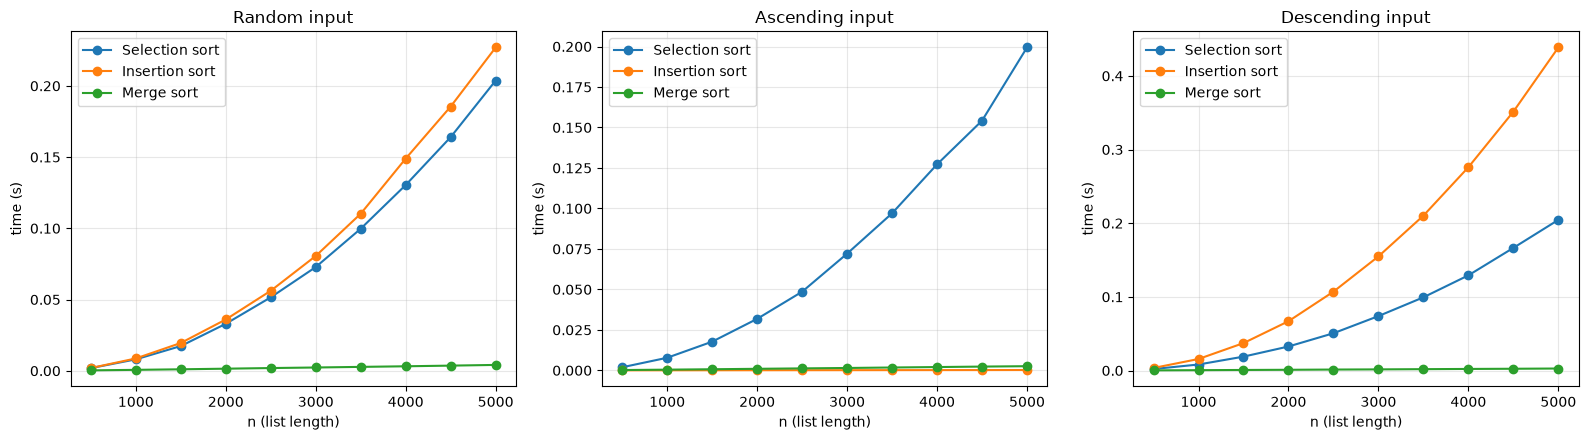

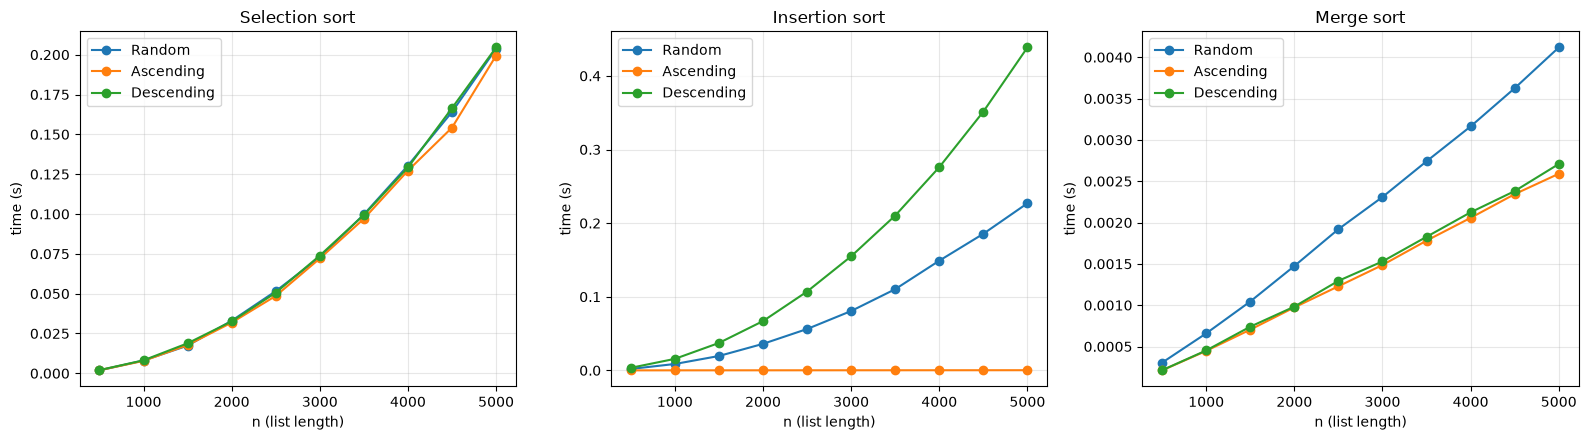

Running time (s) at n = 5000:
  Random     Selection sort: 0.2037, Insertion sort: 0.2269, Merge sort: 0.0041
  Ascending  Selection sort: 0.1994, Insertion sort: 0.0002, Merge sort: 0.0026
  Descending Selection sort: 0.2045, Insertion sort: 0.4386, Merge sort: 0.0027


In [19]:
import random
import time
import matplotlib.pyplot as plt


def measure(sort, data, repeats=3):

    best = float("inf")
    for i in range(repeats):
        copy = list(data)  # selection/insertion sort work in place
        start = time.perf_counter()
        sort(copy)
        best = min(best, time.perf_counter() - start)
    return best


sizes = list(range(500, 5001, 500))
rng = random.Random(42)
inputs = {
    "Random": lambda n: rng.sample(range(n * 10), n),
    "Ascending": lambda n: list(range(n)),
    "Descending": lambda n: list(range(n, 0, -1)),
}
algorithms = {
    "Selection sort": selection_sort,
    "Insertion sort": insertion_sort,
    "Merge sort": merge_sort,
}

# times[input_name][algorithm_name] = list of running times, one per size
times = {name: {alg: [] for alg in algorithms} for name in inputs}
for name, make in inputs.items():
    for n in sizes:
        data = make(n)
        for alg_name, alg in algorithms.items():
            times[name][alg_name].append(measure(alg, data))

# Figure 1: one subplot per input type, comparing the algorithms
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, name in zip(axes, inputs):
    for alg_name in algorithms:
        ax.plot(sizes, times[name][alg_name], marker="o", label=alg_name)
    ax.set_title(f"{name} input")
    ax.set_xlabel("n (list length)")
    ax.set_ylabel("time (s)")
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

# Figure 2: one subplot per algorithm, comparing the input types
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, alg_name in zip(axes, algorithms):
    for name in inputs:
        ax.plot(sizes, times[name][alg_name], marker="o", label=name)
    ax.set_title(alg_name)
    ax.set_xlabel("n (list length)")
    ax.set_ylabel("time (s)")
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

# Times at the largest n, for the discussion below
print(f"Running time (s) at n = {sizes[-1]}:")
for name in inputs:
    row = ", ".join(f"{alg}: {times[name][alg][-1]:.4f}" for alg in algorithms)
    print(f"  {name:<10} {row}")

**Expectations**

| | Random | Ascending | Descending |
|---|---|---|---|
| Selection sort | Θ(n²) | Θ(n²) | Θ(n²) |
| Insertion sort | Θ(n²) (average case) | Θ(n) (best case) | Θ(n²) (worst case) |
| Merge sort | Θ(n log n) | Θ(n log n) | Θ(n log n) |

- *Selection sort* always scans the entire unsorted part to find the minimum, so it makes n(n−1)/2 comparisons no matter what the input looks like. I expect three almost identical parabolas.
- *Insertion sort* depends on how far each element must be moved back. On ascending input the inner `while` loop stops at once, so the running time should be linear and close to zero. Descending input is the worst case: every element is moved all the way to the front, about n²/2 shifts. That is roughly twice the n²/4 shifts expected on random input, so descending should take about twice as long as random.
- *Merge sort* always splits the list in halves and merges every level, so all three inputs should be Θ(n log n). That is far below the two quadratic algorithms. On sorted input (ascending or descending) one half runs out after about n/2 comparisons in each merge, so I expect it to be a little faster than on random input.

**Do the plots match?**

Yes, they match the theory well:

- *Selection sort*: the three curves lie practically on top of each other and grow quadratically. Doubling n from 2000 to 4000 makes the running time about 4 times longer. Descending input is slightly slower because it does more swaps, but comparisons dominate.
- *Insertion sort*: the ascending curve is flat at almost 0 s. Descending is about twice as slow as random (≈ 0.46 s vs ≈ 0.24 s at n = 5000), as predicted. On ascending input insertion sort is the fastest of all three algorithms, even faster than merge sort, because it only makes one pass.
- *Merge sort*: the curves look almost like straight lines (n log n grows only a little faster than n) and are about 50–100× faster than the quadratic sorts at n = 5000. As expected, ascending and descending input are faster than random input (about 1.6× here).

One thing the asymptotic analysis does not show: on random input insertion sort is slightly *slower* than selection sort, even though it makes fewer comparisons (≈ n²/4 vs n²/2). Each step of insertion sort's inner loop does more Python work: two conditions, an element shift and a decrement. Selection sort's inner loop only does one comparison. So the constant factors differ, and that matters in practice even when the Big-O class is the same.